# Structuring ML projects: diagnose, analyse errors, fix data mismatch

A small, real project: train a digit classifier, compare it with a human-level estimate, split the data the right way (train / train-dev / dev / test), find out whether the problem is bias, variance or data mismatch, do an error analysis like the slides, fix the mismatch with synthetic data, and try transfer learning.

[Open in Google Colab](https://colab.research.google.com/github/mahmoudyosrimahmoud13/inpace-library/blob/main/courses/dl-3-ml-projects/files/dl3_ml_strategy.ipynb) · part of the inPace course library. Slides © DeepLearning.AI (CC BY-SA 2.0); this notebook: inPace (CC BY-SA 4.0).

**Run it top to bottom** (Runtime → Run all in Colab). Each part says what to look for.

In [1]:
# Works in Google Colab as it is (PyTorch is already installed there).
# On your own computer:  pip install torch torchvision scikit-learn scipy matplotlib pandas
# One framework per notebook: PyTorch and TensorFlow can clash when loaded into the same Python process.
import numpy as np, matplotlib.pyplot as plt, torch
from torch import nn
torch.manual_seed(0); np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0+cu132 | device: cpu


## 1. The situation
Your **training data** is clean scanned digits. Your **users** take photos with cheap phones: the digits are noisy and a little blurred. The dev and test sets must look like the users' data.

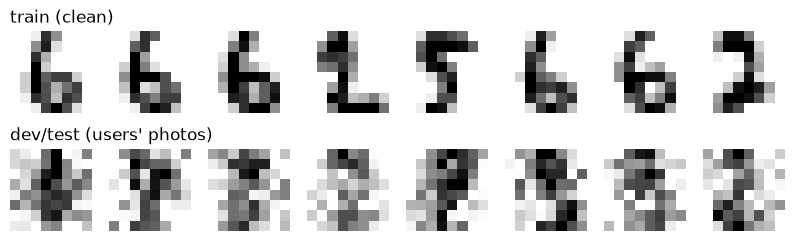

In [2]:
from sklearn.datasets import load_digits
from scipy.ndimage import gaussian_filter
rng = np.random.default_rng(0)
d = load_digits(); Xall, yall = d.images / 16.0, d.target
def phone_photo(imgs):                            # what users' images look like
    return np.clip(gaussian_filter(imgs, sigma=(0, 0.6, 0.6)) + rng.normal(0, 0.25, imgs.shape), 0, 1)
idx = rng.permutation(len(Xall))
clean, users = idx[:1200], idx[1200:]
X_train, y_train = Xall[clean[:1000]], yall[clean[:1000]]           # clean
X_tdev, y_tdev = Xall[clean[1000:]], yall[clean[1000:]]             # train-dev: same distribution as train
X_users, y_users = phone_photo(Xall[users]), yall[users]
X_dev, y_dev, X_test, y_test = X_users[:200], y_users[:200], X_users[200:400], y_users[200:400]
X_photos, y_photos = X_users[400:500], y_users[400:500]          # 100 labelled users' photos, for section 6
fig, ax = plt.subplots(2, 8, figsize=(10, 2.8))
for i in range(8):
    ax[0, i].imshow(X_train[i], cmap="gray_r"); ax[1, i].imshow(X_dev[i], cmap="gray_r")
    ax[0, i].axis("off"); ax[1, i].axis("off")
ax[0, 0].set_title("train (clean)", loc="left"); ax[1, 0].set_title("dev/test (users' photos)", loc="left"); plt.show()

## 2. Train a model and measure four errors

In [3]:
T = lambda a, f=torch.float32: torch.tensor(a, dtype=f)
def train_model(X, y, epochs=300, seed=0):
    torch.manual_seed(seed)
    m = nn.Sequential(nn.Flatten(), nn.Linear(64, 256), nn.ReLU(), nn.Linear(256, 10))
    opt = torch.optim.AdamW(m.parameters(), lr=1e-3, weight_decay=1e-2)
    Xt, yt = T(X), T(y, torch.long)
    for _ in range(epochs):
        opt.zero_grad(); nn.functional.cross_entropy(m(Xt), yt).backward(); opt.step()
    return m
def error(m, X, y):
    with torch.no_grad(): return 1 - (m(T(X)).argmax(1) == T(y, torch.long)).float().mean().item()
model = train_model(X_train, y_train)
human = 0.002  # people misread about 0.2% of clean scans (our estimate of Bayes error for the training data)
errs = {"human level": human, "train": error(model, X_train, y_train), "train-dev": error(model, X_tdev, y_tdev),
        "dev": error(model, X_dev, y_dev)}
for k, v in errs.items(): print(f"{k:<12} {v:6.1%}")
print(f"\navoidable bias  {errs['train'] - human:6.1%}\nvariance        {errs['train-dev'] - errs['train']:6.1%}"
      f"\ndata mismatch   {errs['dev'] - errs['train-dev']:6.1%}   <- the biggest gap is the problem to work on")

human level    0.2%
train          0.4%
train-dev      4.5%
dev           35.0%

avoidable bias    0.2%
variance          4.1%
data mismatch    30.5%   <- the biggest gap is the problem to work on


## 3. Error analysis
Look at the dev examples the model gets wrong. Put each into categories (like the spreadsheet in the slides) and count. Here we let two simple measures do the tagging; in a real project you look at ~100 mistakes yourself.

(if noise didn't matter, about 25% of mistakes would land in each column)
70 mistakes out of 200
very noisy    26% of mistakes
faint         16% of mistakes
dtype: str

most confused pairs:
 true  predicted
8     1            7
6     4            7
1     4            5
5     1            5
0     4            4
dtype: int64


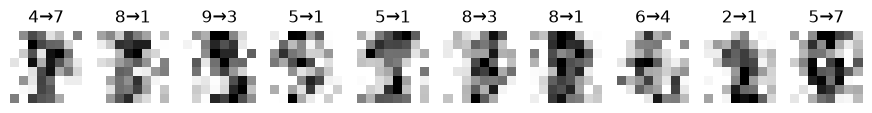

In [4]:
import pandas as pd
with torch.no_grad(): pred = model(T(X_dev)).argmax(1).numpy()
wrong = np.where(pred != y_dev)[0]
noise_all = np.array([np.abs(x - gaussian_filter(x, 1)).mean() for x in X_dev])   # how noisy each dev image is
ink_all = X_dev.mean(axis=(1, 2))                                                # how much ink it has
table = pd.DataFrame({"true": y_dev[wrong], "predicted": pred[wrong],
                      "very noisy": noise_all[wrong] > np.quantile(noise_all, 0.75),   # noisiest quarter of ALL dev images
                      "faint": ink_all[wrong] < np.quantile(ink_all, 0.25)})          # faintest quarter
print("(if noise didn't matter, about 25% of mistakes would land in each column)")
print(len(wrong), "mistakes out of", len(y_dev))
print((table[["very noisy", "faint"]].mean() * 100).round(0).astype(int).astype(str) + "% of mistakes")
print("\nmost confused pairs:\n", table.groupby(["true", "predicted"]).size().sort_values(ascending=False).head(5))
fig, ax = plt.subplots(1, 10, figsize=(11, 1.6))
for a, i in zip(ax, wrong[:10]):
    a.imshow(X_dev[i], cmap="gray_r"); a.set_title(f"{y_dev[i]}→{pred[i]}"); a.axis("off")
plt.show()

## 4. A single number, and a satisficing metric
Pick one number to optimize (here macro F1) and treat others as limits that only need to be good enough (here: prediction time under 1 ms per image).

In [5]:
import time
from sklearn.metrics import f1_score, classification_report
print("macro F1 on dev:", round(f1_score(y_dev, pred, average="macro"), 3))
t0 = time.perf_counter()
with torch.no_grad():
    for _ in range(20): model(T(X_dev))
ms = (time.perf_counter() - t0) / (20 * len(X_dev)) * 1000
print(f"time per image: {ms:.4f} ms -> {'OK' if ms < 1 else 'too slow'}")

macro F1 on dev: 0.644
time per image: 0.0008 ms -> OK


## 5. Fix the data mismatch with synthetic data
Make training images look like the users' photos (noise and blur), add them to the training set, and measure again. Careful: if you synthesize from a tiny set of noise patterns, the model can overfit to them.

In [6]:
X_aug = np.concatenate([X_train, phone_photo(X_train)]); y_aug = np.concatenate([y_train, y_train])
model2 = train_model(X_aug, y_aug)
print(f"dev error before {errs['dev']:.1%} -> after {error(model2, X_dev, y_dev):.1%}")
print(f"test error (look at it only once, at the end): {error(model2, X_test, y_test):.1%}")

dev error before 35.0% -> after 22.5%
test error (look at it only once, at the end): 20.5%


## 6. Transfer learning: same task, new kind of data
You can label only **100 users' photos**. Train on them from scratch, or pre-train on the 1,000 clean scans and then fine-tune the whole network on the 100 photos?

In [7]:
import copy
scratch = train_model(X_photos, y_photos)
tuned = copy.deepcopy(model)                                      # model was pre-trained on the clean scans
opt = torch.optim.AdamW(tuned.parameters(), lr=1e-3)            # small learning rate: adjust, don't erase
for _ in range(150):
    opt.zero_grad(); nn.functional.cross_entropy(tuned(T(X_photos)), T(y_photos, torch.long)).backward(); opt.step()
print(f"dev error, clean scans only:                 {error(model, X_dev, y_dev):.1%}")
print(f"dev error, 100 photos from scratch:          {error(scratch, X_dev, y_dev):.1%}")
print(f"dev error, pre-trained + fine-tuned on them: {error(tuned, X_dev, y_dev):.1%}")

dev error, clean scans only:                 35.0%
dev error, 100 photos from scratch:          38.0%
dev error, pre-trained + fine-tuned on them: 28.0%


## Try this
1. Make `phone_photo` much noisier (`0.5`). Which of the four gaps grows?
2. Train on half the training data. Which gap grows now?
3. In section 5, add only 10% synthetic images. How much of the gain do you keep?
4. In section 6, use 20 photos instead of 100. Does pre-training still help? And when does it stop helping?